# Weighted PageRank (WPR) — Part 5
**Chakib Madcur · Progress update for the 10/27 meeting notes**

Questions from the meeting, and where each is answered:
1. **Is WPR better than standard (unweighted) PageRank?** Tennis only, every season → Step 2
2. **Does the 100th player gain a lot by beating the #1?** Tested experimentally → Step 3
3. **Who gains and who loses under WPR compared with the ATP ranking?** Includes *where in the world* players and tournaments are → Step 4
4. **Women's tennis (WTA)** → Step 5
5. **One table by sport and ranking style** (tournament points, Elo, league, league + playoffs) → Step 6

Only **one coefficient** is used, as agreed: **Spearman's rank correlation** (no cosine similarity).

## Step 1 · Setup
Same method as Part 4: a directed graph per season (**loser → winner**), edge weight = number of wins (WPR) or 1 for every edge (standard PageRank), *d* = 0.85, every player gets the same restart probability, and players with no losses restart uniformly.

The PageRank program below does exactly the same steps as in Part 4, written with NumPy so it runs fast enough for the experiment in Step 3 (hundreds of runs). It is checked against NetworkX again.

**Small fix:** the filter meant to remove the Next Gen Finals did not work, because the dataset spells it "NextGen Finals". It now removes the NextGen Finals and the Laver Cup (neither gives ranking points). This moves earlier Spearman values by at most 0.005.

In [1]:
import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, wilcoxon, binomtest, mannwhitneyu

LOCAL = os.environ.get("LOCAL_DATA")   # optional folder with local copies of the files (faster); otherwise download
def get(url):
    p = os.path.join(LOCAL, url.split("/")[-1]) if LOCAL else None
    return p if p and os.path.exists(p) else url

SACKMANN = "https://raw.githubusercontent.com/Aneeshers/tennis-sackmann-archive/main/"   # copy of Jeff Sackmann's data
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})

def load_atp(year):
    m = pd.read_csv(get(SACKMANN + f"atp/atp_matches_{year}.csv"))
    return m[(m.tourney_level != "D") & (~m.tourney_name.isin(["Next Gen Finals", "NextGen Finals", "Laver Cup"]))
             & (~m.score.astype(str).str.contains("W/O", na=False))]

WTA_TOUR = {"G", "W", "I", "P", "PM", "T1", "T2", "T3", "T4", "T5", "O", "F"}    # tour-level events (no ITF, no team events)
def load_wta(year):
    m = pd.read_csv(get(SACKMANN + f"wta/wta_matches_{year}.csv"))
    return m[m.tourney_level.isin(WTA_TOUR) & (~m.score.astype(str).str.contains("W/O", na=False))]

def directed_graph(losers, winners, weights=None):
    """Directed graph, loser -> winner. Edge weight = sum of the match weights (1 per win by default)."""
    G = nx.DiGraph()
    for i, (l, w) in enumerate(zip(losers, winners)):
        x = 1.0 if weights is None else weights[i]
        if G.has_edge(l, w):
            G[l][w]["weight"] += x
        else:
            G.add_edge(l, w, weight=x)
    return G

def standard_version(G):
    """Same directed graph, but every directed edge has weight 1 (standard PageRank)."""
    H = nx.DiGraph(); H.add_nodes_from(G)
    H.add_edges_from((u, v, {"weight": 1.0}) for u, v in G.edges())
    return H

def weighted_pagerank(G, d=0.85, rounds=200):
    """Random walk: with prob. d follow an edge out of the current player (in proportion to its weight),
    otherwise jump to a random player. Players with no losses restart uniformly."""
    players = list(G); n = len(players); idx = {p: i for i, p in enumerate(players)}
    E = list(G.edges(data="weight"))
    L = np.array([idx[u] for u, v, w in E]); W = np.array([idx[v] for u, v, w in E]); x = np.array([w for u, v, w in E])
    out = np.bincount(L, weights=x, minlength=n)              # total losses of each player
    score = np.full(n, 1 / n)
    for _ in range(rounds):
        unbeaten = score[out == 0].sum()
        score = (1 - d) / n + d * unbeaten / n + np.bincount(W, weights=d * score[L] * x / out[L], minlength=n)
    return pd.Series(score, index=players)

def ranking_files(tour):
    files = ["70s", "80s", "90s", "00s", "10s", "20s"] if tour == "atp" else ["80s", "90s", "00s", "10s", "20s"]
    return pd.concat([pd.read_csv(get(SACKMANN + f"{tour}/{tour}_rankings_{f}.csv")) for f in files])
atp_rankings, wta_rankings = ranking_files("atp"), ranking_files("wta")

def year_end(year, R):
    last = R[R.ranking_date <= year * 10000 + 1231].ranking_date.max()
    return R[R.ranking_date == last].groupby("player")[["rank", "points"]].min().sort_values("rank")

names = {}
def remember_names(m):
    names.update(dict(zip(m.winner_id, m.winner_name)) | dict(zip(m.loser_id, m.loser_name)))

m25 = load_atp(2025); remember_names(m25)
G25 = directed_graph(m25.loser_id, m25.winner_id)
ours, ref = weighted_pagerank(G25), pd.Series(nx.pagerank(G25, alpha=0.85, weight="weight", tol=1e-12))
print(f"2025: {len(m25):,} matches, {G25.number_of_nodes()} players, {G25.number_of_edges()} directed edges")
print(f"Largest difference between our WPR and NetworkX: {(ours - ref[ours.index]).abs().max():.0e}")

2025: 2,646 matches, 292 players, 2389 directed edges
Largest difference between our WPR and NetworkX: 8e-12


## Step 2 · Is WPR better than standard PageRank? (tennis, every season)
Two different questions:
- **Agreement:** which one is closer to the ATP ranking? (Spearman with the ATP year-end ranking, top 100)
- **Prediction:** which one is *better*? Agreement with the ATP is not proof of quality, so I also use each year-end ranking to **predict the winners of all matches in the following season** (the higher-ranked player is the predicted winner). The ATP year-end ranking is predicted the same way, for comparison.

A **paired test** (Wilcoxon signed-rank, season by season) says whether a difference is bigger than chance. I also look only at the matches where two rankings **disagree** about the favourite and count how often each one was right.

In [2]:
def season_table(loader, R, years):
    rows, matches = [], []
    for y in years:
        m = loader(y); G = directed_graph(m.loser_id, m.winner_id)
        w, s, off = weighted_pagerank(G), weighted_pagerank(standard_version(G)), year_end(y, R)
        top = off[(off["rank"] <= 100) & off.index.isin(w.index)]
        row = {"Season": y, "Spearman WPR": spearmanr(top["rank"], -w[top.index])[0],
               "Spearman standard": spearmanr(top["rank"], -s[top.index])[0]}
        try:
            nxt = loader(y + 1)                                   # next season: who won?
            nxt = nxt[nxt.winner_id.isin(w.index) & nxt.loser_id.isin(w.index) & nxt.winner_id.isin(off.index) & nxt.loser_id.isin(off.index)]
            right = lambda a, b: np.where(a == b, 0.5, (a > b).astype(float))     # 1 = winner was ranked higher, 0.5 = tie
            t = pd.DataFrame({"season": y,
                              "official": right(-off["rank"][nxt.winner_id].values, -off["rank"][nxt.loser_id].values),
                              "WPR": right(w[nxt.winner_id].values, w[nxt.loser_id].values),
                              "standard": right(s[nxt.winner_id].values, s[nxt.loser_id].values)})
            row.update({"Next-season matches": len(t), "Accuracy official": t.official.mean(),
                        "Accuracy WPR": t.WPR.mean(), "Accuracy standard": t.standard.mean()})
            matches.append(t)
        except Exception:
            pass                                                  # no next season available
        rows.append(row)
    return pd.DataFrame(rows).set_index("Season"), pd.concat(matches)

def disagreements(t, a, b):
    """Matches where rankings a and b pick different winners: how often was a right?"""
    d = t[(t[a] != t[b]) & (t[a] != 0.5) & (t[b] != 0.5)]
    k = int((d[a] == 1).sum())
    return len(d), k / len(d), binomtest(k, len(d)).pvalue

def report(h, t, label):
    k = h.dropna(subset=["Accuracy WPR"])
    print(f"{label}, {h.index.min()}–{h.index.max()} ({len(h)} seasons)")
    print(f"  Spearman with the official ranking (mean): WPR {h['Spearman WPR'].mean():.3f}, standard {h['Spearman standard'].mean():.3f}; "
          f"WPR higher in {(h['Spearman WPR'] > h['Spearman standard']).sum()} of {len(h)} seasons "
          f"(paired test p = {wilcoxon(h['Spearman WPR'], h['Spearman standard']).pvalue:.3f})")
    print(f"  Next-season matches predicted ({len(t):,} matches): official {t.official.mean():.1%}, WPR {t.WPR.mean():.1%}, standard {t.standard.mean():.1%}")
    print(f"    WPR beats standard in {(k['Accuracy WPR'] > k['Accuracy standard']).sum()} of {len(k)} seasons "
          f"(p = {wilcoxon(k['Accuracy WPR'], k['Accuracy standard']).pvalue:.2f}); "
          f"WPR beats official in {(k['Accuracy WPR'] > k['Accuracy official']).sum()} of {len(k)} (p = {wilcoxon(k['Accuracy WPR'], k['Accuracy official']).pvalue:.2g})")
    for a, b in [("WPR", "standard"), ("WPR", "official")]:
        n, share, p = disagreements(t, a, b)
        print(f"    When {a} and {b} disagree ({n:,} matches), {a}'s favourite won {share:.1%} (p = {p:.2g})")

atp_hist, atp_matches = season_table(load_atp, atp_rankings, range(1973, 2026))
report(atp_hist, atp_matches, "Men (ATP)")
atp_hist.loc[[1980, 1990, 2000, 2010, 2015, 2020, 2024, 2025]].round(3)

Men (ATP), 1973–2025 (53 seasons)
  Spearman with the official ranking (mean): WPR 0.885, standard 0.883; WPR higher in 34 of 53 seasons (paired test p = 0.022)
  Next-season matches predicted (136,756 matches): official 64.4%, WPR 64.5%, standard 64.4%
    WPR beats standard in 31 of 53 seasons (p = 0.08); WPR beats official in 25 of 53 (p = 0.72)
    When WPR and standard disagree (2,983 matches), WPR's favourite won 51.7% (p = 0.062)
    When WPR and official disagree (14,255 matches), WPR's favourite won 50.5% (p = 0.28)


,Spearman WPR,Spearman standard,Next-season matches,Accuracy official,Accuracy WPR,Accuracy standard
Season,,,,,,
1980,0.809,0.806,1380,0.669,0.659,0.664
1990,0.940,0.933,3130,0.615,0.620,0.621
2000,0.891,0.878,2743,0.604,0.607,0.606
2010,0.929,0.928,2543,0.651,0.644,0.643
2015,0.936,0.928,2405,0.659,0.663,0.659
2020,0.700,0.700,2272,0.613,0.609,0.608
2024,0.935,0.927,2391,0.627,0.624,0.620
2025,0.915,0.914,1202,0.637,0.634,0.632


**What this says**
- WPR is **closer to the ATP ranking** than standard PageRank in most seasons, and the difference is statistically real but **small**.
- For **predicting the next season**, WPR, standard PageRank and the ATP ranking are **equally good** (all about 64%). So WPR is *not* a better predictor than the ATP ranking, and only slightly (not significantly) better than standard PageRank.
- Why so small in tennis? Most pairs of players meet **only once** in a season, so most edges have weight 1 and the two versions are almost the same graph. Step 6 shows that weighting matters much more in leagues, where the same teams meet again and again.

## Step 3 · Experiment: the 100th player beats the world #1
**Question:** if the #100 player beats the #1, does WPR reward it much more than the ATP ranking does?

**Experiment (2025 season):** take the real 2025 graph, add **one extra win** for the ATP #100 player over one opponent, recompute WPR, and see how many places he gains. Repeat for opponents of different ranks.

**ATP for comparison:** ATP points depend on the *round and tournament*, not on the opponent. A first-round win at a Grand Slam is worth 50 − 10 = **+40 points** (2024 ATP points table), whether the opponent is #1 or #200.

In [3]:
atp25 = year_end(2025, atp_rankings)
in_graph = atp25[atp25.index.isin(list(G25))]
def position(score, p):
    return int((score > score[p]).sum()) + 1

def with_extra_win(G, winner, loser):
    H = G.copy()
    if H.has_edge(loser, winner):
        H[loser][winner]["weight"] += 1
    else:
        H.add_edge(loser, winner, weight=1.0)
    return H

player = in_graph.index[in_graph["rank"] >= 100][0]
w0 = weighted_pagerank(G25); losses = {q: G25.out_degree(q, weight="weight") for q in G25}
print(f"Player: {names[player]} (ATP #{int(in_graph.loc[player, 'rank'])}, {int(in_graph.loc[player, 'points'])} points), "
      f"tour-level record {(m25.winner_id == player).sum()}–{(m25.loser_id == player).sum()}, WPR rank {position(w0, player)}")

rows = []
for q in in_graph[in_graph["rank"] <= 200].index:
    if q == player:
        continue
    w1 = weighted_pagerank(with_extra_win(G25, player, q))
    rows.append({"id": q, "Opponent": names[q], "Opponent ATP rank": int(atp25.loc[q, "rank"]), "Opponent losses in 2025": int(losses[q]),
                 "WPR rank after the win": position(w1, player), "Places gained (WPR)": position(w0, player) - position(w1, player),
                 "Opponent's WPR rank after": position(w1, q)})
upset = pd.DataFrame(rows)
pts = in_graph.points.copy(); before = position(pts, player); pts[player] += 40
print(f"ATP: +40 points moves him from #{before} to #{position(pts, player)} ({before - position(pts, player)} places), whoever the opponent is")
upset[upset["Opponent ATP rank"].isin([1, 2, 3, 4, 5, 10, 20, 31, 50, 75, 150, 200])].set_index("Opponent").drop(columns="id")

Player: Tristan Schoolkate (ATP #100, 641 points), tour-level record 6–9, WPR rank 114


ATP: +40 points moves him from #100 to #88 (12 places), whoever the opponent is


,Opponent ATP rank,Opponent losses in 2025,WPR rank after the win,Places gained (WPR),Opponent's WPR rank after
Opponent,,,,,
Carlos Alcaraz,1,8,50,64,1
Jannik Sinner,2,6,53,61,2
Alexander Zverev,3,23,101,13,5
Novak Djokovic,4,11,88,26,3
Felix Auger Aliassime,5,24,102,12,6
Jack Draper,10,9,88,26,9
Tommy Paul,20,13,102,12,29
Valentin Vacherot,31,4,97,17,52
Jenson Brooksby,50,15,106,8,42


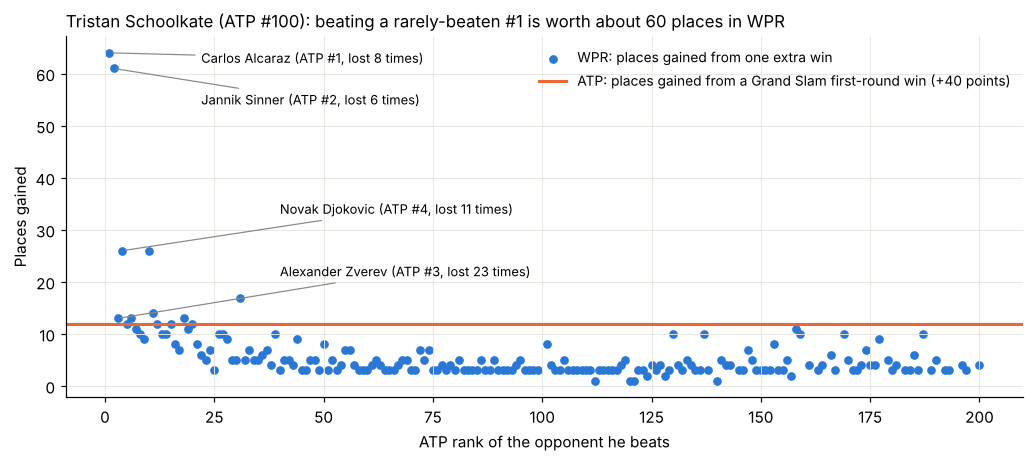

Spearman(places gained, opponent's ATP rank) = 0.44
Spearman(places gained, opponent's WPR score / (losses + 1)) = 0.96


In [4]:
fig, ax = plt.subplots(figsize=(9.5, 4.3))
ax.scatter(upset["Opponent ATP rank"], upset["Places gained (WPR)"], s=22, color=BLUE, label="WPR: places gained from one extra win")
ax.axhline(before - position(pts, player), color=ORANGE, lw=2, label="ATP: places gained from a Grand Slam first-round win (+40 points)")
label_at = {1: (22, 63), 2: (22, 55), 4: (40, 34), 3: (40, 22)}       # where to write each label (empty part of the chart)
for _, r in upset[upset["Opponent ATP rank"].isin(label_at)].iterrows():
    ax.annotate(f"{r['Opponent']} (ATP #{r['Opponent ATP rank']}, lost {r['Opponent losses in 2025']} times)",
                (r["Opponent ATP rank"], r["Places gained (WPR)"]), xytext=label_at[r["Opponent ATP rank"]], fontsize=8.5, va="center",
                arrowprops=dict(arrowstyle="-", color=GREY, lw=0.8))
ax.set_xlabel("ATP rank of the opponent he beats"); ax.set_ylabel("Places gained")
ax.set_title(f"{names[player]} (ATP #100): beating a rarely-beaten #1 is worth about 60 places in WPR", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper right", fontsize=9)
plt.tight_layout(); plt.savefig("upset_experiment.png", dpi=200); plt.show()

value = upset["id"].map(lambda q: w0[q] / (losses[q] + 1))     # score the opponent passes on per loss
print(f"Spearman(places gained, opponent's ATP rank) = {spearmanr(upset['Places gained (WPR)'], -upset['Opponent ATP rank'])[0]:.2f}")
print(f"Spearman(places gained, opponent's WPR score / (losses + 1)) = {spearmanr(upset['Places gained (WPR)'], value)[0]:.2f}")

**Is this only one player and one season?** Repeat it (a) for **all 21 players ranked 90–110** in 2025, and (b) in **every season since 1990**, each time with that season's ATP #100 beating that season's ATP #1.

In [5]:
one, p200 = in_graph.index[in_graph["rank"] == 1][0], in_graph.index[in_graph["rank"] >= 200][0]
res = []
for p in in_graph[(in_graph["rank"] >= 90) & (in_graph["rank"] <= 110)].index:
    res.append({"before": position(w0, p), "beats #1": position(weighted_pagerank(with_extra_win(G25, p, one)), p),
                "beats #200": position(weighted_pagerank(with_extra_win(G25, p, p200)), p)})
res = pd.DataFrame(res)
print(f"2025, players ranked 90–110 (n = {len(res)}): median WPR rank {res.before.median():.0f} -> {res['beats #1'].median():.0f} after beating {names[one]}, "
      f"-> {res['beats #200'].median():.0f} after beating {names[p200]} (#200)")

rows = []
for y in range(1990, 2026):
    m = load_atp(y); remember_names(m); G = directed_graph(m.loser_id, m.winner_id); off = year_end(y, atp_rankings)
    ig = off[off.index.isin(list(G))]; p, top1 = ig.index[ig["rank"] >= 100][0], ig.index[ig["rank"] == 1][0]
    H = with_extra_win(G, p, top1)
    w_b, w_a = weighted_pagerank(G), weighted_pagerank(H)
    s_b, s_a = weighted_pagerank(standard_version(G)), weighted_pagerank(standard_version(H))
    rows.append({"Season": y, "ATP #1": names[top1], "Losses of the #1": int(G.out_degree(top1, weight="weight")),
                 "WPR: places gained": position(w_b, p) - position(w_a, p), "Standard: places gained": position(s_b, p) - position(s_a, p)})
upsets = pd.DataFrame(rows).set_index("Season")
print(f"1990–2025: median places gained, WPR {upsets['WPR: places gained'].median():.0f}, standard {upsets['Standard: places gained'].median():.0f}; "
      f"WPR gives more in {(upsets['WPR: places gained'] > upsets['Standard: places gained']).sum()} of {len(upsets)} seasons; "
      f"smallest jump {upsets['WPR: places gained'].min()} places")
print(f"Spearman(places gained, fewer losses of the #1) = {spearmanr(upsets['WPR: places gained'], -upsets['Losses of the #1'])[0]:.2f}")
upsets.sort_values("WPR: places gained", ascending=False).head(6)

2025, players ranked 90–110 (n = 21): median WPR rank 104 -> 45 after beating Carlos Alcaraz, -> 101 after beating Oliver Crawford (#200)


1990–2025: median places gained, WPR 39, standard 32; WPR gives more in 30 of 36 seasons; smallest jump 7 places
Spearman(places gained, fewer losses of the #1) = 0.74


,ATP #1,Losses of the #1,WPR: places gained,Standard: places gained
Season,,,,
2006,Roger Federer,5,142,141
2005,Roger Federer,4,114,92
2019,Rafael Nadal,7,113,104
2007,Roger Federer,9,97,80
2008,Rafael Nadal,11,89,78
2015,Novak Djokovic,6,86,62


**Result (confirmed experimentally):** yes. One win over the #1 moves a #100 player up about **60 places in WPR** (in 2025, and for all players ranked 90–110), against **12 places** in the ATP ranking and only a few places for a win over a #200 player. In all 36 seasons since 1990 the jump is positive (median 39 places), it is bigger with WPR than with standard PageRank in 30 of them, and it is largest when the #1 **rarely lost** (Federer in 2005–06 lost only 4–5 matches).

The reason: a win is worth the opponent's WPR score **divided by how many times he lost**. That explains the gain far better (Spearman 0.96) than the opponent's ATP rank does. Beating Zverev (ATP #3, but 25 losses in 2025) gives much less than beating Alcaraz or Sinner (9 and 6 losses). Losing does not lower the #1's own WPR rank in this test: WPR rewards wins, it does not subtract for losses.

## Step 4 · Who gains and who loses under WPR compared with the ATP ranking?
For the ATP top 100 in each season 2010–2025 (1,598 player-seasons), **gain** = (position by ATP) − (position by WPR) within the top 100. Positive gain = WPR ranks the player **higher** than the ATP does. Then I relate gain to simple facts about each player's season.

In [6]:
CONTINENT = {}
for c in "ESP FRA GER ITA RUS CZE SRB CRO BEL GBR SUI SWE NED AUT SVK ROU FIN POL UKR POR BLR BUL HUN CYP SLO DEN GEO LUX BIH LAT GRE NOR LTU MDA ARM MON EST MNE SCG TUR ISR".split():
    CONTINENT[c] = "Europe"
for c in "USA CAN JAM DOM MEX PUR".split(): CONTINENT[c] = "North America"
for c in "ARG BRA CHI COL URU ECU PER PAR BOL VEN".split(): CONTINENT[c] = "South America"
for c in "JPN KAZ KOR TPE UZB THA CHN IND INA PHI".split(): CONTINENT[c] = "Asia"
for c in "AUS NZL".split(): CONTINENT[c] = "Oceania"
for c in "RSA MAR TUN ZIM EGY MAD".split(): CONTINENT[c] = "Africa"
country = pd.read_csv(get(SACKMANN + "atp/atp_players.csv"), low_memory=False).set_index("player_id").ioc

BIG = {"G", "M", "F"}            # Grand Slams, Masters 1000, ATP Finals
rows = []
for y in range(2010, 2026):
    m = load_atp(y); remember_names(m); G = directed_graph(m.loser_id, m.winner_id); w = weighted_pagerank(G); off = year_end(y, atp_rankings)
    top = off[(off["rank"] <= 100) & off.index.isin(w.index)].copy()
    top["gain"] = top["rank"].rank() - (-w[top.index]).rank()
    for p in top.index:
        won, lost = m[m.winner_id == p], m[m.loser_id == p]; both = pd.concat([won, lost])
        rows.append({"Season": y, "Player": names[p], "ATP rank": int(top.loc[p, "rank"]), "Gain": top.loc[p, "gain"],
                     "Tour-level matches": len(both), "Win %": len(won) / len(both), "Share at big events": both.tourney_level.isin(BIG).mean(),
                     "Wins over top-20": int((won.loser_rank <= 20).sum()), "Share on clay": (both.surface == "Clay").mean(),
                     "Continent": CONTINENT.get(country.get(p), "Other")})
X = pd.DataFrame(rows)
factors = ["Tour-level matches", "Wins over top-20", "Win %", "Share on clay", "Share at big events"]
pd.DataFrame({"Spearman with gain": [spearmanr(X[f], X.Gain)[0] for f in factors]}, index=factors).round(2)

,Spearman with gain
Tour-level matches,0.18
Wins over top-20,0.19
Win %,0.04
Share on clay,-0.03
Share at big events,-0.11


In [7]:
print("Gain by number of tour-level matches played:")
display(X.groupby(pd.cut(X["Tour-level matches"], [0, 20, 30, 40, 60, 100]), observed=True).Gain.agg(["count", "mean"]).round(1))
print("Gain by share of matches at Grand Slams / Masters / Finals:")
display(X.groupby(pd.cut(X["Share at big events"], [0, .3, .45, .6, .75, 1]), observed=True).Gain.agg(["count", "mean"]).round(1))
print("Biggest losers and gainers under WPR, 2025:")
X[X.Season == 2025].sort_values("Gain").iloc[[0, 1, 2, 3, -4, -3, -2, -1]].set_index("Player").drop(columns="Season").round(2)

Gain by number of tour-level matches played:


,count,mean
Tour-level matches,,
"(0, 20]",274,-8.1
"(20, 30]",222,0.8
"(30, 40]",284,2.9
"(40, 60]",613,1.7
"(60, 100]",205,0.9


Gain by share of matches at Grand Slams / Masters / Finals:


,count,mean
Share at big events,,
"(0.0, 0.3]",347,1.5
"(0.3, 0.45]",613,1.5
"(0.45, 0.6]",432,-0.9
"(0.6, 0.75]",142,-4.5
"(0.75, 1.0]",48,-7.0


Biggest losers and gainers under WPR, 2025:


,ATP rank,Gain,Tour-level matches,Win %,Share at big events,Wins over top-20,Share on clay,Continent
Player,,,,,,,,
Sebastian Baez,45,-33.0,41,0.41,0.34,0,0.61,South America
Valentin Royer,57,-30.0,21,0.48,0.52,1,0.05,Europe
Terence Atmane,63,-26.0,17,0.41,0.59,2,0.24,Europe
Luciano Darderi,25,-23.0,56,0.52,0.34,1,0.52,Europe
Reilly Opelka,52,20.0,48,0.52,0.46,4,0.12,North America
Nuno Borges,47,20.0,57,0.51,0.49,4,0.25,Europe
Roberto Bautista Agut,90,23.0,37,0.41,0.41,3,0.38,Europe
Benjamin Bonzi,94,32.0,35,0.43,0.60,3,0.11,Europe


**Location.** Does *where* a player comes from, or where he plays, matter? First by the player's continent (2010–2025):

In [8]:
t = X.groupby("Continent").agg(players=("Gain", "size"), mean_gain=("Gain", "mean"), share_on_clay=("Share on clay", "mean")).round(2)
display(t.sort_values("mean_gain"))
sa = X[X.Continent == "South America"].Gain; rest = X[X.Continent != "South America"].Gain
print(f"South American players vs everyone else: mean gain {sa.mean():.1f} vs {rest.mean():.1f} (Mann–Whitney p = {mannwhitneyu(sa, rest).pvalue:.3f})")

,players,mean_gain,share_on_clay
Continent,,,
South America,164,-2.03,0.53
Asia,90,-0.28,0.21
Europe,1066,0.14,0.32
North America,182,0.20,0.17
Oceania,77,0.43,0.14
Africa,19,7.26,0.17


South American players vs everyone else: mean gain -2.0 vs 0.2 (Mann–Whitney p = 0.014)


Then by **where the tournaments are played.** An ATP 250 title gives 250 points everywhere, but the players you beat are not equally strong everywhere. For all ATP 250 matches 2010–2025, the table shows the **median year-end ATP rank of the beaten player**, by continent of the tournament (tournament locations entered by hand).

In [9]:
REGION = {}
for t in ["Antalya", "Antwerp", "Athens", "Banja Luka", "Barcelona", "Basel", "Bastad", "Belgrade", "Belgrade ", "Belgrade 2", "Brussels", "Bucharest",
          "Budapest", "Cagliari", "Cologne 1", "Cologne 2", "Dusseldorf", "Eastbourne", "Estoril", "Florence", "Geneva", "Gijon", "Gstaad", "Halle",
          "Hamburg", "Istanbul", "Kitzbuhel", "Lyon", "Madrid Masters", "Mallorca", "Marbella", "Marseille", "Metz", "Monte Carlo Masters", "Montpellier",
          "Moscow", "Munich", "Naples", "Nice", "Nottingham", "Paris Masters", "Paris Olympics", "Parma", "Queen's Club", "Roland Garros", "Rome Masters",
          "Rotterdam", "Sardinia", "Sofia", "St Petersburg", "St. Petersburg", "Stockholm", "Stuttgart", "Umag", "Valencia", "Vienna", "Wimbledon",
          "Zagreb", "s Hertogenbosch", "London Olympics", "Tour Finals"]: REGION[t] = "Europe"
for t in ["Almaty", "Astana", "Nur-Sultan", "Bangkok", "Beijing", "Chengdu", "Chennai", "Doha", "Dubai", "Hangzhou", "Hong Kong", "Kuala Lumpur",
          "Pune", "Seoul", "Shanghai Masters", "Shenzhen", "Singapore", "Tokyo", "Tokyo Olympics", "Zhuhai", "Tel Aviv"]: REGION[t] = "Asia"
for t in ["Adelaide", "Adelaide 1", "Adelaide 2", "Auckland", "Australian Open", "Brisbane", "Great Ocean Road Open", "Melbourne",
          "Murray River Open", "Sydney", "Atp Cup", "United Cup"]: REGION[t] = "Oceania"
for t in ["Acapulco", "Atlanta", "Canada Masters", "Cincinnati Masters", "Dallas", "Delray Beach", "Houston", "Indian Wells Masters", "Los Angeles",
          "Los Cabos", "Memphis", "Miami Masters", "New Haven", "New York", "Newport", "San Diego", "San Jose", "US Open", "Us Open", "Washington",
          "Winston-Salem"]: REGION[t] = "North America"
for t in ["ATP Rio de Janeiro", "Rio De Janeiro", "Rio de Janeiro", "Bogota", "Buenos Aires", "Cordoba", "Costa Do Sauipe", "Quito", "Rio Olympics",
          "Santiago", "Sao Paulo", "Vina del Mar"]: REGION[t] = "South America"
for t in ["Casablanca", "Johannesburg", "Marrakech"]: REGION[t] = "Africa"

rows = []
for y in range(2010, 2026):
    m = load_atp(y); off = year_end(y, atp_rankings)
    a = m[(m.tourney_level == "A") & (~m.tourney_name.isin(["Atp Cup", "United Cup"]))]
    rows.append(pd.DataFrame({"Region": a.tourney_name.map(REGION), "Tournament": a.tourney_id,
                              "Beaten player's year-end rank": off["rank"].reindex(a.loser_id).values, "Clay": a.surface == "Clay"}))
R = pd.concat(rows)
assert R.Region.notna().all()
R.groupby("Region").agg(tournaments=("Tournament", "nunique"), matches=("Clay", "size"),
                        median_rank_of_beaten_player=("Beaten player's year-end rank", "median"),
                        share_on_clay=("Clay", "mean")).round(2).sort_values("median_rank_of_beaten_player")

,tournaments,matches,median_rank_of_beaten_player,share_on_clay
Region,,,,
Asia,110,3224,63.0,0.00
Oceania,47,1340,68.0,0.00
Europe,427,12430,70.0,0.43
North America,137,4417,85.0,0.11
South America,62,1775,89.0,0.92
Africa,16,450,97.0,0.86


**What this says**
- **The ATP rewards one big run; WPR rewards whom you beat.** Players with few tour-level matches or with most of their matches at Grand Slams and Masters are ranked lower by WPR. Example: Valentin Vacherot won the 2025 Shanghai Masters as a qualifier. That is 1,000 ATP points from one tournament, but in WPR it is only 11 tour-level wins.
- **Part of the ATP ranking comes from Challenger events**, which are not in our tour-level graph. Players who earn many points there (few tour-level matches) lose places in WPR: **−8 places** on average for players with 20 or fewer tour-level matches.
- **Wins over top-20 players** are what WPR rewards most.
- **Location:** South American players are ranked about **2 places lower** by WPR than by the ATP (p ≈ 0.01). Their seasons are clay-heavy, and the ATP 250 events in South America (and North America and Africa) have **weaker fields**: the median beaten player is ranked about 85–97, against 63–70 in Asia, Oceania and Europe. The same 250 points come with fewer wins over strong players, so WPR gives less credit.

## Step 5 · Women's tennis (WTA), 1984–2025
Same analysis with the WTA tour-level matches (Grand Slams, WTA tournaments, Olympics and Finals; no ITF events, no team events) and the WTA year-end ranking.

In [10]:
wta_hist, wta_matches = season_table(load_wta, wta_rankings, range(1984, 2026))
report(wta_hist, wta_matches, "Women (WTA)")
print(f"Men over the same years 1984–2025: mean Spearman WPR {atp_hist.loc[1984:2025, 'Spearman WPR'].mean():.3f}")
wta_hist.loc[[1990, 2000, 2010, 2015, 2020, 2024, 2025]].round(3)

Women (WTA), 1984–2025 (42 seasons)
  Spearman with the official ranking (mean): WPR 0.904, standard 0.903; WPR higher in 31 of 42 seasons (paired test p = 0.009)
  Next-season matches predicted (87,376 matches): official 64.9%, WPR 64.5%, standard 64.4%
    WPR beats standard in 25 of 42 seasons (p = 0.20); WPR beats official in 9 of 42 (p = 0.00034)
    When WPR and standard disagree (1,818 matches), WPR's favourite won 51.9% (p = 0.12)
    When WPR and official disagree (8,178 matches), WPR's favourite won 47.8% (p = 6e-05)
Men over the same years 1984–2025: mean Spearman WPR 0.896


,Spearman WPR,Spearman standard,Next-season matches,Accuracy official,Accuracy WPR,Accuracy standard
Season,,,,,,
1990,0.850,0.842,2294,0.672,0.667,0.663
2000,0.945,0.949,2308,0.649,0.647,0.650
2010,0.945,0.941,2298,0.634,0.638,0.631
2015,0.910,0.906,2381,0.611,0.614,0.614
2020,0.722,0.731,2067,0.618,0.613,0.619
2024,0.882,0.877,2199,0.616,0.613,0.613
2025,0.877,0.874,1132,0.624,0.633,0.618


**What this says:** WPR agrees with the WTA ranking about as well as with the ATP ranking (mean Spearman 0.90), and again WPR is slightly closer than standard PageRank. One difference: for women, the **official WTA ranking predicts the next season better than WPR** (about 65% vs 64.5%, significant), while for men the two are tied. In 2020 both tours froze their rankings during COVID, which is why agreement drops to about 0.7 that year for both.

## Step 6 · One table: sports and ranking styles
The same WPR on every sport, compared with the official ranking by Spearman.

| Ranking style | How the official ranking works | Data here |
|---|---|---|
| **Tournament points** | points for how far you go in each tournament, last 52 weeks | ATP, WTA |
| **Elo rating** | each result moves your rating depending on the opponent's rating | FIFA men's ranking (Elo-based since 2018) |
| **League table** | everyone plays everyone, points for wins and draws | Premier League |
| **League + playoffs** | unbalanced regular season, then playoffs; regular-season record | NBA, NHL, NFL |

**Games per pair met** = matches ÷ number of different pairs that met. It is about 1 in tennis (most players meet once) and 2–3 in leagues.

*FIFA ranking:* the full list of 18 July 2024 as published by GiveMeSport (the most recent full list I could access), compared with all international matches between FIFA members from 16 Aug 2018, when FIFA switched to its Elo method, to 18 July 2024 (dataset by Mart Jürisoo). A draw counts as half a win each way, as in Part 4.

In [11]:
def structure(losers, winners):
    pairs = pd.Series([frozenset(p) for p in zip(losers, winners)])
    n = len(set(losers) | set(winners))
    return {"Competitors": n, "Games per pair met": len(pairs) / pairs.nunique(), "Pairs met": pairs.nunique() / (n * (n - 1) / 2)}

def compare(losers, winners, weights, official, higher_is_better=True):
    G = directed_graph(losers, winners, weights); w, s = weighted_pagerank(G), weighted_pagerank(standard_version(G))
    o = official[official.index.isin(w.index)] * (1 if higher_is_better else -1)
    return {"Spearman WPR": spearmanr(o, w[o.index])[0], "Spearman standard": spearmanr(o, s[o.index])[0], "Compared": len(o)}

def games_to_edges(home, away, hs, as_):
    L, W, X_ = [], [], []
    for h, a, x, y in zip(home, away, hs, as_):
        if x > y: L.append(a); W.append(h); X_.append(1.0)
        elif x < y: L.append(h); W.append(a); X_.append(1.0)
        else: L += [h, a]; W += [a, h]; X_ += [0.5, 0.5]          # draw: half a win each way
    return L, W, X_

table = {}
for name, loader, R in [("Men's tennis (ATP) 2025", load_atp, atp_rankings), ("Women's tennis (WTA) 2025", load_wta, wta_rankings)]:
    m = loader(2025); top100 = year_end(2025, R)["rank"]; top100 = top100[top100 <= 100]
    table[name] = {"Ranking style": "Tournament points"} | structure(m.loser_id, m.winner_id) | compare(m.loser_id, m.winner_id, None, top100, False)

fifa = pd.read_csv(get("https://raw.githubusercontent.com/ChakibMadcur/tennis-pagerank-research/main/data/fifa_ranking_2024_07_18.csv"))
fifa["team"] = fifa.team.replace({"USA": "United States", "Turkiye": "Turkey", "Czechia": "Czech Republic", "Congo DR": "DR Congo",
    "Bosnia & Herzegovina": "Bosnia and Herzegovina", "Curacao": "Curaçao", "Trinidad & Tobago": "Trinidad and Tobago", "Kyrgyz Republic": "Kyrgyzstan",
    "Korea DPR": "North Korea", "St Kitts and Nevis": "Saint Kitts and Nevis", "Chinese Taipei": "Taiwan", "Papa New Guinea": "Papua New Guinea",
    "St Lucia": "Saint Lucia", "St Vincent and the Grenadines": "Saint Vincent and the Grenadines", "Brunei Darussalam": "Brunei",
    "Sao Tome and Principe": "São Tomé and Príncipe", "US Virgin Islands": "United States Virgin Islands"})
fifa = fifa.set_index("team")["rank"]
r = pd.read_csv(get("https://raw.githubusercontent.com/martj42/international_results/master/results.csv")); r["date"] = pd.to_datetime(r.date)
r = r[(r.date >= "2018-08-16") & (r.date <= "2024-07-18") & r.home_team.isin(fifa.index) & r.away_team.isin(fifa.index)]
L, W, X_ = games_to_edges(r.home_team, r.away_team, r.home_score, r.away_score)
table["International football 2018–24 (all 210)"] = {"Ranking style": "Elo rating (FIFA)"} | structure(r.home_team, r.away_team) | compare(L, W, X_, fifa, False)
table["International football 2018–24 (FIFA top 50)"] = {"Ranking style": "Elo rating (FIFA)"} | structure(r.home_team, r.away_team) | compare(L, W, X_, fifa[fifa <= 50], False)

NHL_POINTS = {"COL": 121, "CAR": 113, "DAL": 112, "BUF": 109, "TBL": 106, "MTL": 106, "MIN": 104, "BOS": 100, "OTT": 99, "PIT": 98,
              "PHI": 98, "WSH": 95, "VGK": 95, "EDM": 93, "CBJ": 92, "DET": 92, "UTA": 92, "ANA": 92, "NYI": 91, "LAK": 90, "NJD": 87,
              "STL": 86, "NSH": 86, "SJS": 86, "FLA": 84, "WPG": 82, "SEA": 79, "TOR": 78, "NYR": 77, "CGY": 77, "CHI": 72, "VAN": 58}
def league(name):
    if name.startswith("Premier"):
        d = pd.read_csv(get("https://raw.githubusercontent.com/datasets/football-datasets/main/datasets/premier-league/season-2526.csv"))
        return d.HomeTeam, d.AwayTeam, d.FTHG, d.FTAG
    if name.startswith("NFL"):
        d = pd.read_csv(get("https://raw.githubusercontent.com/nflverse/nfldata/master/data/games.csv"), low_memory=False)
        d = d[(d.season == 2025) & (d.game_type == "REG")]
        return d.home_team, d.away_team, d.home_score, d.away_score
    if name.startswith("NBA"):
        d = pd.read_parquet(get("https://raw.githubusercontent.com/sportsdataverse/hoopR-nba-data/main/nba/schedules/parquet/nba_schedule_2026.parquet"))
        d = d[(d.season_type == 2) & (d.type_abbreviation == "STD") & (d.status_type_completed == True)]
        d = d[~d.notes_headline.fillna("").str.contains("All-Star|Cup Championship")]
        return d.home_display_name, d.away_display_name, d.home_score, d.away_score
    d = pd.read_parquet(get("https://raw.githubusercontent.com/sportsdataverse/fastRhockey-nhl-data/main/nhl/schedules/parquet/nhl_schedule_2026.parquet"))
    d = d[d.game_type == "R"]
    return d.home_team_abbr, d.away_team_abbr, d.home_score, d.away_score

def official_table(home, away, hs, as_, name):
    t = pd.DataFrame({"team": list(home) + list(away), "f": list(hs) + list(as_), "a": list(as_) + list(hs)})
    T = t.assign(W=t.f > t.a, D=t.f == t.a).groupby("team").agg(G=("f", "size"), W=("W", "sum"), D=("D", "sum"))
    if name.startswith("Premier"): return 3 * T.W + T.D                       # league points
    if name.startswith("NHL"): return pd.Series(NHL_POINTS, dtype=float)       # official points
    return (T.W + 0.5 * T.D) / T.G                                             # win percentage

for name, style in [("Premier League 2025–26", "League table"), ("NBA 2025–26", "League + playoffs"),
                    ("NHL 2025–26", "League + playoffs"), ("NFL 2025", "League + playoffs")]:
    h, a, x, y = league(name); L, W, X_ = games_to_edges(h, a, x, y)
    table[name] = {"Ranking style": style} | structure(h, a) | compare(L, W, X_, official_table(h, a, x, y, name))

sports = pd.DataFrame(table).T
numbers = ["Competitors", "Games per pair met", "Pairs met", "Spearman WPR", "Spearman standard", "Compared"]
sports[numbers] = sports[numbers].astype(float)
sports["Gain from weighting"] = sports["Spearman WPR"] - sports["Spearman standard"]
sports.style.format({"Competitors": "{:.0f}", "Games per pair met": "{:.2f}", "Pairs met": "{:.0%}", "Spearman WPR": "{:.3f}",
                     "Spearman standard": "{:.3f}", "Compared": "{:.0f}", "Gain from weighting": "{:+.3f}"})

,Ranking style,Competitors,Games per pair met,Pairs met,Spearman WPR,Spearman standard,Compared,Gain from weighting
Men's tennis (ATP) 2025,Tournament points,292,1.17,5%,0.915,0.914,100,+0.001
Women's tennis (WTA) 2025,Tournament points,336,1.15,4%,0.877,0.874,98,+0.003
International football 2018–24 (all 210),Elo rating (FIFA),210,1.95,13%,0.947,0.955,210,-0.008
International football 2018–24 (FIFA top 50),Elo rating (FIFA),210,1.95,13%,0.771,0.653,50,+0.119
Premier League 2025–26,League table,20,2.00,100%,0.956,0.799,20,+0.157
NBA 2025–26,League + playoffs,30,2.83,100%,0.962,0.876,30,+0.085
NHL 2025–26,League + playoffs,32,2.65,100%,0.875,0.815,32,+0.061
NFL 2025,League + playoffs,32,1.21,45%,0.888,0.880,32,+0.008


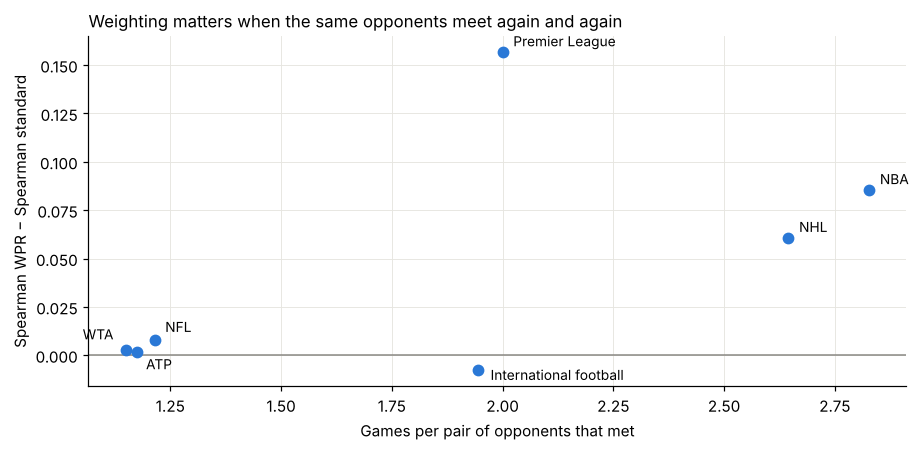

Spearman across these sports (games per pair vs gain): 0.64


In [12]:
s = sports.drop(index="International football 2018–24 (FIFA top 50)")
short = {"Men's tennis (ATP) 2025": "ATP", "Women's tennis (WTA) 2025": "WTA", "International football 2018–24 (all 210)": "International football",
         "Premier League 2025–26": "Premier League", "NBA 2025–26": "NBA", "NHL 2025–26": "NHL", "NFL 2025": "NFL"}
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.axhline(0, color=GREY, lw=1)
ax.scatter(s["Games per pair met"], s["Gain from weighting"], s=45, color=BLUE, zorder=3)
offset = {"ATP": (6, -11), "WTA": (-8, 7), "NFL": (7, 5), "International football": (8, -3)}
for k, row in s.iterrows():
    dx, dy = offset.get(short[k], (7, 4))
    ax.annotate(short[k], (row["Games per pair met"], row["Gain from weighting"]), xytext=(dx, dy), textcoords="offset points", fontsize=9,
                ha="right" if dx < 0 else "left", va="center" if short[k] == "International football" else "baseline")
ax.set_xlabel("Games per pair of opponents that met"); ax.set_ylabel("Spearman WPR − Spearman standard")
ax.set_title("Weighting matters when the same opponents meet again and again", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig("weighting_gain_by_sport.png", dpi=200); plt.show()
print("Spearman across these sports (games per pair vs gain):", round(spearmanr(s["Games per pair met"], s["Gain from weighting"])[0], 2))

**Chess and golf.** Both fit the framework but are not in the table yet:
- **Chess** uses an Elo rating (FIDE). WPR needs a file of classical games between rated players, and I could not get one in a clean, open, downloadable form this week.
- **Golf** (Official World Golf Ranking) is not head-to-head: 150 players play the same tournament. The graph would need a different construction, for example "every player who finished ahead of you beat you" in each tournament. That is a next step.

## Findings
1. **WPR vs standard PageRank (tennis):** WPR agrees with the ATP ranking better in most seasons (statistically real, but small: 0.885 vs 0.883). For predicting the next season, they are **equally good**, about 64%.
2. **Can we say WPR is better?** Better than *standard PageRank*: yes for agreement with official rankings, clearly so in leagues (Premier League 0.96 vs 0.80). Better than *the ATP ranking*: **no**. All three predict next-season matches equally well. WPR's value is as an **independent check**: it uses only who beat whom, and it agrees with the ATP at about 0.9.
3. **Is high correlation good or bad?** Both. It shows that the ATP points system mostly agrees with head-to-head results. The interesting part is **where they differ** (point 5).
4. **The #100 beats #1 experiment:** confirmed. One such win is worth about **60 places in WPR** but only **12 places in the ATP**. What matters is how rarely the beaten player loses, not his ATP rank.
5. **Who gains and who loses:** WPR favours players with **many tour-level wins and wins over top-20 players**. It is less kind to players whose ATP points come from **one big run** or from **Challenger events**, and to **South American clay-court players**, whose regional ATP 250 events have weaker fields.
6. **Women's tennis:** very similar agreement (0.90). Here the official WTA ranking predicts the next season slightly better than WPR.
7. **Across sports:** weighting matters in proportion to **how often the same opponents meet**. It helps a lot in leagues (Premier League, NBA, NHL), and very little in tennis and the NFL. Agreement with the official ranking is lowest when the official ranking uses information WPR does not have: COVID freezes (tennis 2020), points from other tours (Challengers), or teams from different continents that rarely meet (FIFA top 50: 0.77).